In [46]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [47]:
from utils import *

In [48]:
import warnings

def fxn():
    warnings.warn("deprecated", RuntimeWarning)
with warnings.catch_warnings(action="ignore"):
    fxn()

In [49]:
d, n = 50 , 10000
X = np.random.randn( n, d )
y = ( np.sum( X , axis = 1 ) <= 0.5 ).astype(np.int64)

In [50]:
_ = binary_classification(X,y,0.01,5000)

Epochs 1 | Loss 2.2471902679267606 | Accuracy 0.565
Epochs 101 | Loss 2.0124439925632243 | Accuracy 0.5823
Epochs 201 | Loss 1.7952835312502775 | Accuracy 0.6017
Epochs 301 | Loss 1.5958705087690166 | Accuracy 0.6205
Epochs 401 | Loss 1.4141485802024842 | Accuracy 0.6409
Epochs 501 | Loss 1.2498118192869556 | Accuracy 0.6612
Epochs 601 | Loss 1.1023513266733145 | Accuracy 0.6806
Epochs 701 | Loss 0.9710707697281555 | Accuracy 0.6998
Epochs 801 | Loss 0.8550618371153607 | Accuracy 0.7194
Epochs 901 | Loss 0.7532169515849899 | Accuracy 0.739
Epochs 1001 | Loss 0.6643098187515787 | Accuracy 0.7568
Epochs 1101 | Loss 0.5871096224497789 | Accuracy 0.7745
Epochs 1201 | Loss 0.5204225410617821 | Accuracy 0.7923
Epochs 1301 | Loss 0.46307731089055754 | Accuracy 0.8087
Epochs 1401 | Loss 0.41394176041553055 | Accuracy 0.8208
Epochs 1501 | Loss 0.37195822776104714 | Accuracy 0.8353
Epochs 1601 | Loss 0.33616581555747255 | Accuracy 0.8478
Epochs 1701 | Loss 0.30570594242166105 | Accuracy 0.8612
E

In [51]:
# Caricamento del dataset
train = MNIST(root="./data", train=True, download=True)
test = MNIST(root="./data", train=False, download=True)

# Conversione in NumPy e normalizzazione
X_train = train.data.numpy().astype(np.float32) / 255.0
X_test = test.data.numpy().astype(np.float32) / 255.0

# 0 = cifra <= 5, 1 = cifra > 5
y_train = (train.targets.numpy() > 5).astype(np.int64)
y_test = (test.targets.numpy() > 5).astype(np.int64)

# Flatten delle immagini
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

In [52]:
idx = np.random.choice( np.arange( X_train.shape[0] ) , size = 5000 , replace=False )
w = binary_classification( X_train[idx,:] , y_train[idx] , 0.1 , 20000 )

Epochs 1 | Loss 3.2963526327343105 | Accuracy 0.4986
Epochs 101 | Loss 1.2304215013117514 | Accuracy 0.6618
Epochs 201 | Loss 0.8623773207098988 | Accuracy 0.73
Epochs 301 | Loss 0.7163659671384894 | Accuracy 0.7648
Epochs 401 | Loss 0.6395640732065045 | Accuracy 0.7842
Epochs 501 | Loss 0.591307409178313 | Accuracy 0.8002
Epochs 601 | Loss 0.5572286172866618 | Accuracy 0.808
Epochs 701 | Loss 0.5312499881086086 | Accuracy 0.8146
Epochs 801 | Loss 0.5103799799625025 | Accuracy 0.8196
Epochs 901 | Loss 0.4929749450932769 | Accuracy 0.8248
Epochs 1001 | Loss 0.478063082816727 | Accuracy 0.8282
Epochs 1101 | Loss 0.4650361446988464 | Accuracy 0.8318
Epochs 1201 | Loss 0.45349246820269545 | Accuracy 0.834
Epochs 1301 | Loss 0.4431524472975754 | Accuracy 0.8358
Epochs 1401 | Loss 0.43381172875560126 | Accuracy 0.8386
Epochs 1501 | Loss 0.4253147503920871 | Accuracy 0.8394
Epochs 1601 | Loss 0.4175393419416599 | Accuracy 0.8406
Epochs 1701 | Loss 0.41038736021207234 | Accuracy 0.8434
Epochs 

In [53]:
y_test_pred = classify(w,X_test)
test_accuracy = accuracy(y_test,y_test_pred)
print(f'Test accuracy = {test_accuracy}')

Test accuracy = 0.8645


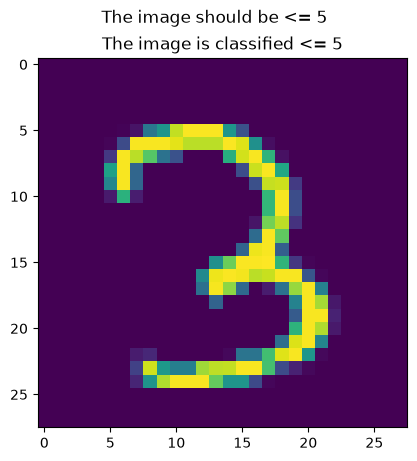

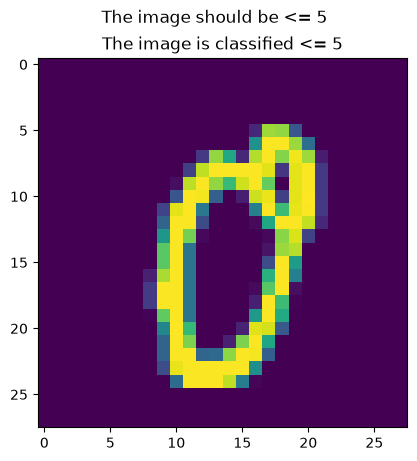

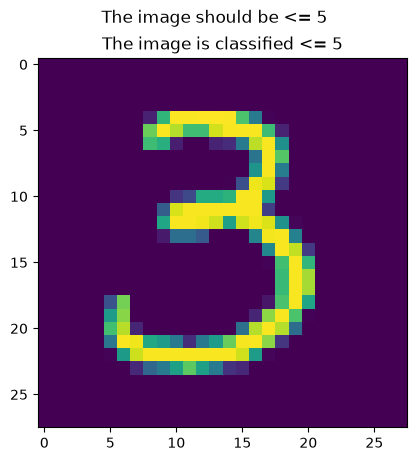

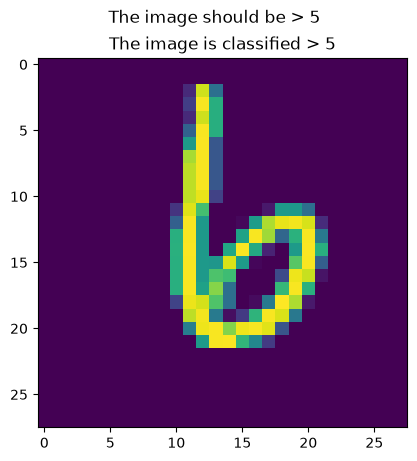

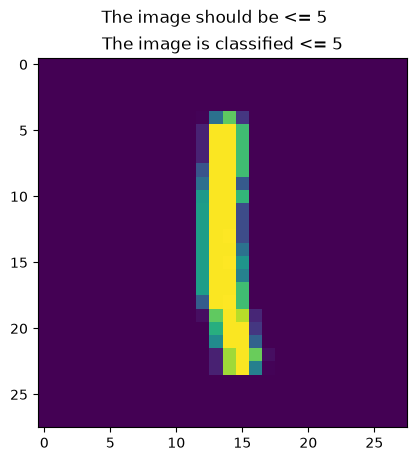

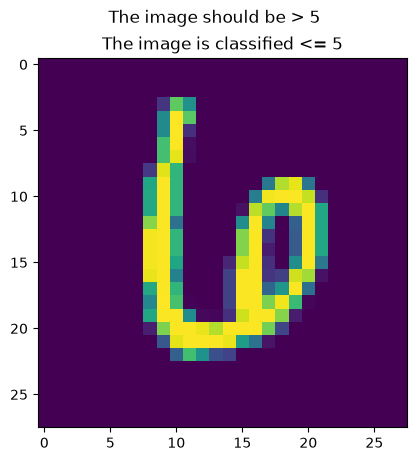

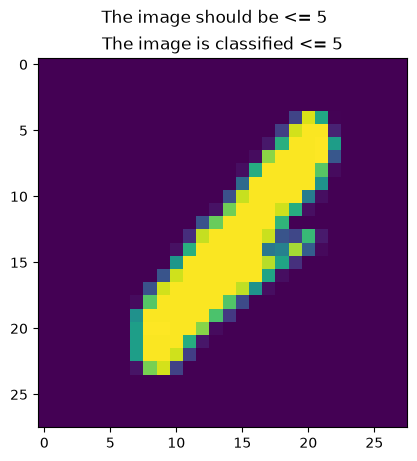

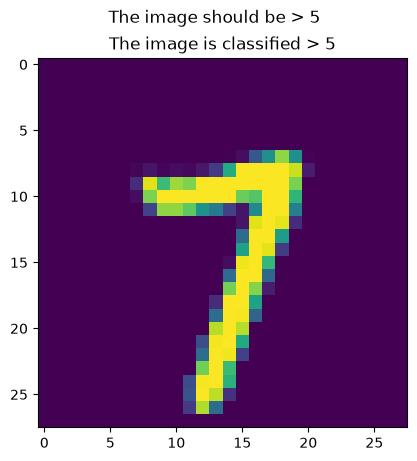

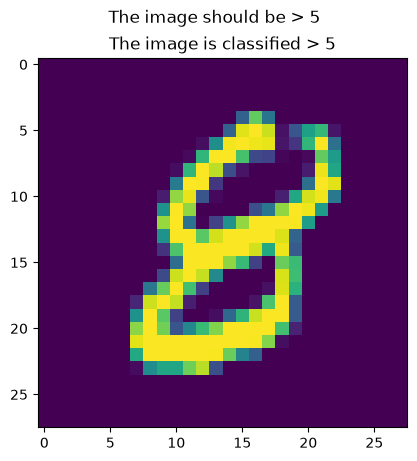

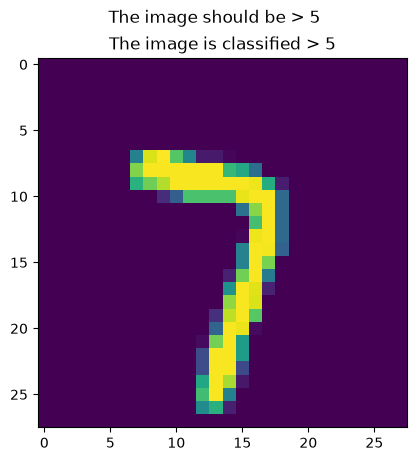

In [54]:
classif = { 0.: '<= 5', 1.:'> 5' }
for k in np.random.choice( np.arange(5000) , size = 10 , replace=False):
    x_plot = X_test[k,:].reshape(28,-1)
    plt.imshow(x_plot)
    plt.suptitle(f'The image should be {classif[ y_test[k] ]}')
    plt.title(f'The image is classified {classif[ y_test_pred[k] ]}')
    plt.show()